# Laboratorio 4 - Segmentación de imágenes con técnicas de agrupación

*Presentado por:*
- Shaiel Jiménez - 202323846
- Juan Esteban Triviño - 202315338

*ISIS2611 - Aprendizaje de Máquina / Sección 5*

*Profesor: Rubén Manrique*

**Contenido**

- [Introducción](#introduccion)
- [Configuración del entorno](#entorno)
- [Exploración de las imágenes de ajuste](#exploracion)
- [Actividad 1 - Pipeline de preparación y representación](#actividad1)

## <a id="introduccion"></a> Introducción

DermAlpes es una empresa de telemedicina que conecta centros de salud de municipios pequeños con dermatólogos de las ciudades principales. El personal toma fotografías de las lesiones de piel con un dermatoscopio y las envía para que un especialista las revise a distancia, y la empresa quiere una herramienta que delimite automáticamente la lesión para que el dermatólogo pueda medir su tamaño y forma. Como no cuenta con imágenes etiquetadas de sus pacientes, quiere saber si es posible segmentar la lesión sin entrenar un modelo supervisado, agrupando los píxeles según su color y su posición. La herramienta no hace diagnósticos, solo delimita la lesión.

En este laboratorio se construye ese método sobre 20 imágenes públicas que incluyen máscaras de referencia hechas por especialistas. Cada píxel se representa con su color y su posición, ponderados por β y λ, y se agrupa con K-medias, eligiendo el número de grupos con el coeficiente de silueta. Luego se define un criterio para decidir qué grupos forman la lesión, se ajusta la configuración con 15 imágenes y se evalúa sin cambios en las 5 restantes. Por último se analiza dónde falla el método y qué riesgos tendría usarlo con pacientes, cámaras o condiciones de luz distintas.

## <a id="entorno"></a> Configuración del entorno

In [1]:
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import sklearn
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, v_measure_score, f1_score, precision_score, recall_score

SEMILLA = 42

print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

numpy 2.5.4 | pandas 3.1.0 | scikit-learn 1.9.1


### Datos

Se usan 20 imágenes dermatoscópicas del conjunto ISIC 2016, tarea de segmentación de lesiones ([enlace](https://challenge.isic-archive.com/landing/2016/37/)), cada una con su máscara de referencia elaborada por especialistas. Siguiendo el enunciado, 15 imágenes son de ajuste y 5 de prueba. Las de prueba y sus máscaras no se abren hasta la Actividad 5, así que aquí solo se comprueba que los archivos existen.

Los datos van en *data/raw/ajuste* y *data/raw/prueba*, con los nombres originales (*ISIC_0000085.jpg* y *ISIC_0000085_Segmentation.png*). Las rutas se arman con *pathlib* y son relativas a la carpeta del notebook, para que funcionen igual en macOS, Linux o Windows.

In [2]:
DATA_DIR = Path("data") / "raw"

IDS_AJUSTE = ["ISIC_0000085", "ISIC_0000086", "ISIC_0000089", "ISIC_0000094", "ISIC_0000108",
              "ISIC_0000114", "ISIC_0000116", "ISIC_0000122", "ISIC_0000133", "ISIC_0000137",
              "ISIC_0000150", "ISIC_0000153", "ISIC_0000156", "ISIC_0000157", "ISIC_0000112"]
IDS_PRUEBA = ["ISIC_0000087", "ISIC_0000105", "ISIC_0000110", "ISIC_0000123", "ISIC_0000128"]

def carpeta(id_img):
    return DATA_DIR / ("prueba" if id_img in IDS_PRUEBA else "ajuste")

def ruta_imagen(id_img):
    return carpeta(id_img) / f"{id_img}.jpg"

def ruta_mascara(id_img):
    return carpeta(id_img) / f"{id_img}_Segmentation.png"

# Solo se verifica que existan los archivos, sin abrirlos
todos = IDS_AJUSTE + IDS_PRUEBA
faltantes = [str(r) for i in todos for r in (ruta_imagen(i), ruta_mascara(i)) if not r.exists()]
print(f"IDs: {len(IDS_AJUSTE)} de ajuste + {len(IDS_PRUEBA)} de prueba = {len(set(todos))}")
print(f"Archivos esperados: {2 * len(todos)} | faltantes: {len(faltantes)} {faltantes if faltantes else ''}")
print("IDs en ajuste y prueba a la vez:", set(IDS_AJUSTE) & set(IDS_PRUEBA))

IDs: 15 de ajuste + 5 de prueba = 20
Archivos esperados: 40 | faltantes: 0 
IDs en ajuste y prueba a la vez: set()


## <a id="exploracion"></a> Exploración de las imágenes de ajuste

### Carga y verificación

Se cargan las 15 imágenes de ajuste con sus máscaras y se revisa lo que el enunciado da por hecho: que cada máscara tiene el mismo tamaño que su imagen y solo los valores 0 (piel o fondo) y 255 (lesión).

In [3]:
def cargar(id_img):
    img = np.array(Image.open(ruta_imagen(id_img)).convert("RGB"))
    mascara = np.array(Image.open(ruta_mascara(id_img)))
    return img, mascara

originales = {i: cargar(i) for i in IDS_AJUSTE}

filas = []
for id_img, (img, mascara) in originales.items():
    assert img.shape[:2] == mascara.shape, f"{id_img}: tamaños distintos"
    filas.append({"id": id_img, "alto": img.shape[0], "ancho": img.shape[1],
                  "ancho/alto": round(img.shape[1] / img.shape[0], 2),
                  "valores máscara": sorted(np.unique(mascara).tolist()),
                  "% lesión": round((mascara > 127).mean() * 100, 1)})
resumen_ajuste = pd.DataFrame(filas).set_index("id")
resumen_ajuste

,alto,ancho,ancho/alto,valores máscara,% lesión
id,,,,,
ISIC_0000085,1536,2048,1.33,"[0, 255]",12.7
ISIC_0000086,1944,2592,1.33,"[0, 255]",23.4
ISIC_0000089,1536,2048,1.33,"[0, 255]",12.1
ISIC_0000094,1536,2048,1.33,"[0, 255]",5.9
ISIC_0000108,1536,2048,1.33,"[0, 255]",18.5
ISIC_0000114,1536,2048,1.33,"[0, 255]",3.1
ISIC_0000116,1536,2048,1.33,"[0, 255]",36.1
ISIC_0000122,1536,2048,1.33,"[0, 255]",39.0
ISIC_0000133,1536,2048,1.33,"[0, 255]",14.2


**Hallazgos.** Las 15 máscaras son binarias y coinciden en tamaño con su imagen, así que no requieren corrección. Casi todas las imágenes miden 2048 x 1536 píxeles; dos son más grandes (086 y 153) y una más pequeña y menos ancha (157). La lesión ocupa entre el 3.1% y el 39% de la imagen (mediana de 23.4%), de modo que un criterio basado en el tamaño del grupo no sería confiable. Con imágenes de más de tres millones de píxeles, agrupar a resolución completa sería muy costoso, por eso más adelante se reducen.

### Vista general

K-medias solo ve el color y la posición de cada píxel, así que cualquier cosa con un color parecido al de la lesión, como pelos, bordes oscuros del lente o marcas, puede terminar en su mismo grupo. Se muestran las 15 imágenes con el contorno de la máscara de referencia para ver qué casos tendrá que enfrentar el método.

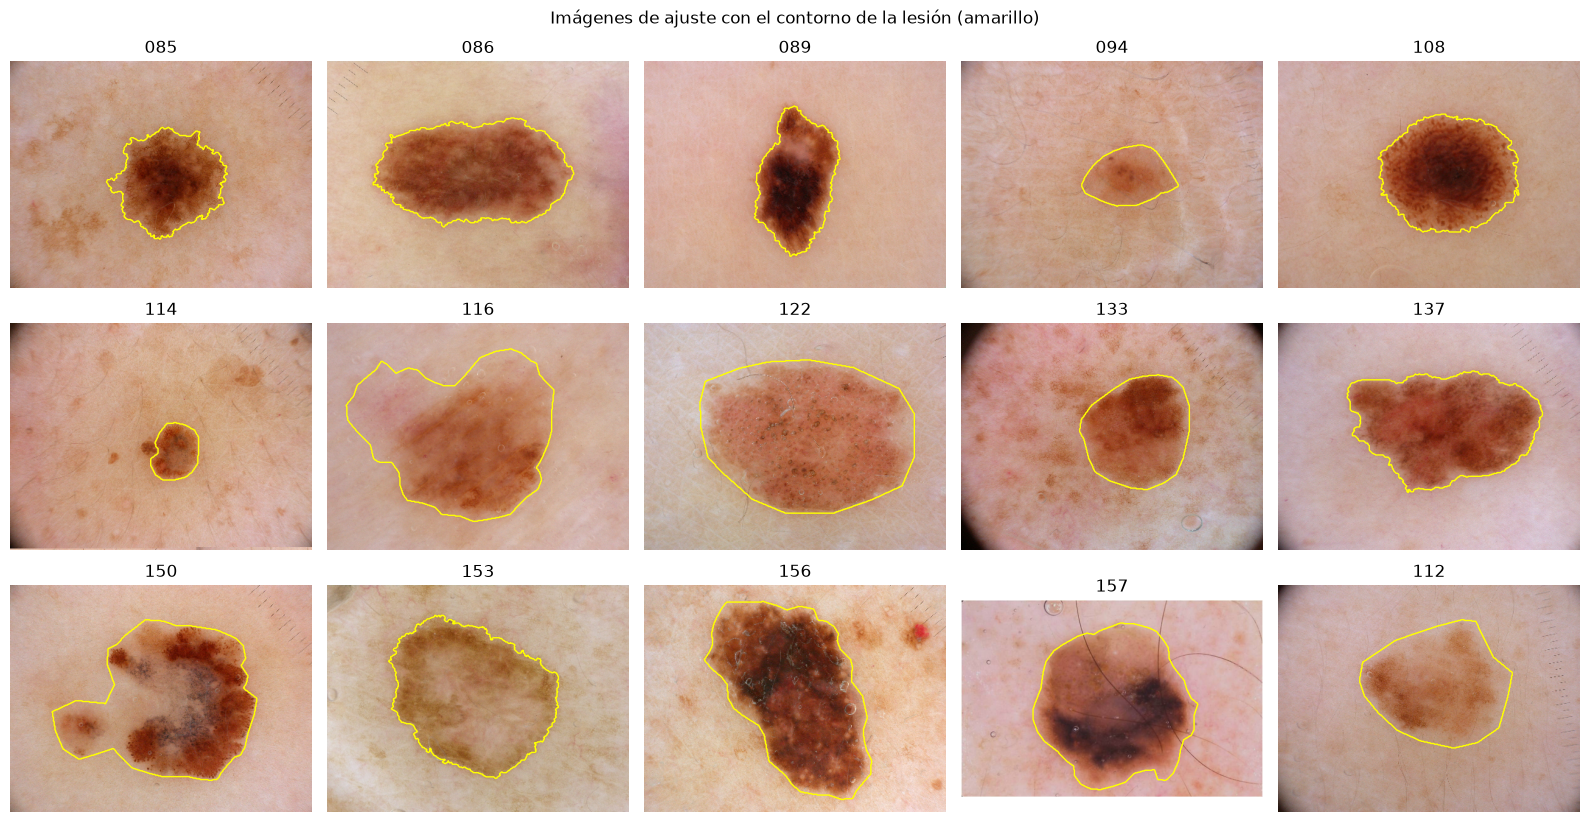

In [4]:
fig, axes = plt.subplots(3, 5, figsize=(16, 8.5))
for ax, (id_img, (img, mascara)) in zip(axes.ravel(), originales.items()):
    paso = max(1, img.shape[1] // 400)  # se submuestrea solo para dibujar
    ax.imshow(img[::paso, ::paso])
    ax.contour(mascara[::paso, ::paso], levels=[127], colors="yellow", linewidths=1)
    ax.set_title(id_img[-3:])
    ax.axis("off")
plt.suptitle("Imágenes de ajuste con el contorno de la lesión (amarillo)")
plt.tight_layout()
plt.show()

**Hallazgos.** En casi todas las imágenes la lesión es café, más oscura que la piel y está cerca del centro, que son las condiciones que favorecen a un método basado en color y posición. Aun así aparecen varios casos difíciles. En 133 las esquinas son negras por el lente, y en 112, 114 y 137 se oscurecen un poco, lo que puede confundirse con la lesión. Varias imágenes tienen una regla o marcas de medida en el borde (por ejemplo 085, 133, 137, 150 y 156), y en 157 hay pelos gruesos que cruzan la lesión. Algunas lesiones tienen poco contraste con la piel o son muy claras (094, 112 y parte de 116), y otras combinan zonas oscuras y claras (089, 150, 153 y 157), así que la lesión podría quedar repartida en más de un grupo. También hay pecas o manchas fuera de la lesión (085, 114 y 133) y un punto rojo en 156. Por último, algunas máscaras de referencia tienen un contorno suave y redondeado (094, 112, 116 y 122), con lo que parte de la piel cercana queda dentro de la lesión de referencia, mientras que otras siguen el borde con detalle.

### Cómo es la lesión frente a la piel

Antes de proponer un criterio para reconocer la lesión conviene medir si de verdad es más oscura que la piel y si suele estar en el centro. Para cada imagen se calcula la ubicación del centro de la lesión (en coordenadas de 0 a 1), su distancia al centro de la imagen, si toca el borde, la luminosidad media (promedio de R, G y B entre 0 y 1) de la lesión y de la piel, y la distancia de color entre ambas. Las máscaras solo se usan aquí para describir, no para agrupar.

In [ ]:
def describir(img, mascara, paso=4):
    img = img[::paso, ::paso] / 255.0  # submuestreo para no recorrer millones de píxeles
    lesion = mascara[::paso, ::paso] > 127
    alto, ancho = lesion.shape
    filas, columnas = np.nonzero(lesion)
    cx, cy = columnas.mean() / (ancho - 1), filas.mean() / (alto - 1)
    color_lesion, color_piel = img[lesion].mean(axis=0), img[~lesion].mean(axis=0)
    return {"centro x": cx, "centro y": cy,
            "dist. al centro": np.hypot(cx - 0.5, cy - 0.5),
            "toca borde": bool(lesion[0].any() or lesion[-1].any() or lesion[:, 0].any() or lesion[:, -1].any()),
            "lum. lesión": color_lesion.mean(), "lum. piel": color_piel.mean(),
            "dist. color": np.linalg.norm(color_lesion - color_piel)}

descriptivos = pd.DataFrame([describir(*originales[i]) for i in IDS_AJUSTE], index=IDS_AJUSTE)
descriptivos.insert(0, "% lesión", resumen_ajuste["% lesión"])
display(descriptivos.round(2))
descriptivos.drop(columns="toca borde").describe().loc[["min", "50%", "max"]].round(2)

**Hallazgos.** En las 15 imágenes de ajuste la lesión es más oscura que la piel (luminosidad de 0.29 a 0.53 frente a 0.60 a 0.74), está muy cerca del centro (su centro queda a 0.09 o menos del centro de la imagen) y no toca el borde. Esto respalda dos ideas para reconocer el grupo de la lesión: que sea el más oscuro y que esté hacia el centro. La distancia de color entre lesión y piel va de 0.24 a 0.72 (mediana 0.48), y las de menor contraste son 112, 094 y 116, que ya se veían difíciles en la vista general. Son solo 15 imágenes, así que estas regularidades describen este conjunto y no tienen por qué cumplirse con otras fotos.

### Resolución de trabajo

Cada píxel es una fila de datos, y con más de tres millones de píxeles por imagen agrupar y calcular la silueta sería muy lento (la silueta crece con el cuadrado del número de puntos). Por eso cada imagen se reduce conservando su proporción: la imagen con interpolación bilineal y la máscara con vecino más cercano, para que siga teniendo solo ceros y unos. Como las coordenadas se normalizan entre 0 y 1, λ significa lo mismo a cualquier resolución.

Para elegir el tamaño se mide cuánto detalle del contorno se pierde: cada máscara se reduce, se vuelve a ampliar y se compara con la original mediante el coeficiente de Dice. Se fijó de antemano usar 128 píxeles de lado mayor si el Dice medio es al menos 0.98, y 192 si no.

In [ ]:
def reducir(img, mascara, lado):
    escala = lado / max(img.shape[:2])
    tamano = (round(img.shape[1] * escala), round(img.shape[0] * escala))  # Pillow usa (ancho, alto)
    img_r = np.array(Image.fromarray(img).resize(tamano, Image.BILINEAR))
    mascara_r = np.array(Image.fromarray(mascara).resize(tamano, Image.NEAREST))
    return img_r, (mascara_r > 127).astype(np.uint8)

def dice(a, b):
    # Igual a f1_score con la lesión como clase positiva, pero más rápido a resolución completa
    a, b = a.astype(bool), b.astype(bool)
    return 2 * (a & b).sum() / (a.sum() + b.sum())

techo = {}
for lado in [96, 128, 192, 256]:
    valores = []
    for img, mascara in originales.values():
        _, chica = reducir(img, mascara, lado)
        ampliada = np.array(Image.fromarray(chica).resize(mascara.shape[::-1], Image.NEAREST))
        valores.append(dice(ampliada, mascara > 127))
    techo[lado] = {"Dice medio": np.mean(valores), "Dice mínimo": np.min(valores)}
pd.DataFrame(techo).T.rename_axis("lado mayor (px)").round(4)

**Hallazgos.** Al reducir a 128 píxeles de lado mayor, la máscara conserva casi todo su contorno (Dice medio de 0.9885 y mínimo de 0.9746 frente a la original), y pasar a 192 o 256 solo mejora en milésimas. Se trabaja a 128 píxeles, que deja unos 12 mil píxeles por imagen, y esa resolución se mantiene igual para todas las configuraciones y para la prueba. Esto también marca un techo: aunque el método acertara perfectamente, su Dice no podría superar ese valor por la pérdida de detalle en el borde.

## <a id="actividad1"></a> Actividad 1 - Pipeline de preparación y representación

### Imágenes reducidas y máscaras de 0 y 1

Cada imagen de ajuste se reduce a 128 píxeles de lado mayor y su máscara pasa de 0 y 255 a 0 y 1, donde 1 es la lesión, como pide el enunciado.

In [ ]:
LADO = 128
datos_ajuste = {i: reducir(*originales[i], LADO) for i in IDS_AJUSTE}

tamanos = pd.Series({i: img.shape[:2] for i, (img, _) in datos_ajuste.items()}).value_counts()
print("Tamaños reducidos (alto, ancho):", tamanos.to_dict())
print("Valores de las máscaras:", sorted(set(np.concatenate([m.ravel() for _, m in datos_ajuste.values()]).tolist())))

### De la imagen a una matriz de píxeles

Cada imagen se convierte en una matriz con una fila por píxel y cinco columnas: R, G y B divididos entre 255, y las coordenadas x (columna) e y (fila) divididas entre el ancho y el alto menos uno. Así las cinco columnas quedan entre 0 y 1. Esto importa porque K-medias agrupa por distancias, y si el color fuera de 0 a 255 y la posición de 0 a 128, el color pesaría más solo por su escala. El orden de las filas es el mismo de la máscara aplanada, lo que permite comparar luego cada píxel con su etiqueta de referencia.

In [ ]:
def imagen_a_matriz(img):
    alto, ancho = img.shape[:2]
    filas, columnas = np.mgrid[0:alto, 0:ancho]
    color = img.reshape(-1, 3) / 255.0
    x = columnas.ravel() / (ancho - 1)
    y = filas.ravel() / (alto - 1)
    return np.column_stack([color, x, y])

img, mascara = datos_ajuste["ISIC_0000085"]
X = imagen_a_matriz(img)
print("Forma:", X.shape, "| píxeles de la imagen:", img.shape[0] * img.shape[1])
pd.DataFrame({"mínimo": X.min(axis=0), "máximo": X.max(axis=0)}, index=["R", "G", "B", "x", "y"]).round(3)

### Pesos β y λ

El transformador *PesosBetaLambda* multiplica las columnas de color por β y las de posición por λ. Como β y λ son parámetros del transformador, se pueden cambiar con *set_params* sin tocar el código. No aprende nada de los datos, por eso *fit* solo devuelve el mismo objeto.

Con estos pesos, la distancia al cuadrado entre dos píxeles queda β² · (distancia de color² + (λ/β)² · distancia de posición²). El factor β² multiplica todas las distancias por igual, así que no cambia qué centroide queda más cerca de cada píxel: lo único que cuenta es la razón λ/β. Con λ = 0 solo se usa el color y con β = 0 solo la posición.

In [ ]:
class PesosBetaLambda(BaseEstimator, TransformerMixin):
    def __init__(self, beta=1.0, lam=0.0):
        self.beta = beta
        self.lam = lam

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return X * np.array([self.beta] * 3 + [self.lam] * 2)

pesos = PesosBetaLambda(beta=2, lam=0.5)
print("Máximo por columna con beta=2 y lam=0.5:", pesos.fit_transform(X).max(axis=0).round(3))
print("Máximo por columna con beta=0 (solo posición):", pesos.set_params(beta=0, lam=1).transform(X).max(axis=0).round(3))

### Pipeline completo

El pipeline encadena los tres pasos: convertir la imagen en matriz, aplicar los pesos y agrupar con K-medias. Cada imagen se agrupa por separado, porque sus colores y su iluminación son propios, y β, λ y K se cambian con *set_params*. K-medias usa 10 inicializaciones (*n_init*) y la semilla fija, porque solo garantiza un mínimo local y el resultado depende de dónde empiece.

In [ ]:
pipeline = Pipeline([
    ("pixeles", FunctionTransformer(imagen_a_matriz)),
    ("pesos", PesosBetaLambda()),
    ("kmeans", KMeans(n_init=10, random_state=SEMILLA)),
])

def agrupar(img, beta, lam, k):
    pipeline.set_params(pesos__beta=beta, pesos__lam=lam, kmeans__n_clusters=k).fit(img)
    return pipeline.named_steps["kmeans"].labels_.reshape(img.shape[:2])

img, mascara = datos_ajuste["ISIC_0000085"]
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
axes[0].imshow(img)
axes[0].set_title("Imagen reducida")
for ax, (beta, lam) in zip(axes[1:], [(1, 0), (1, 0.5), (0, 1)]):
    ax.imshow(agrupar(img, beta, lam, 3), cmap="tab10")
    ax.set_title(f"K=3, beta={beta}, lambda={lam}")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

### Solo importa la razón λ/β

Si se multiplican β y λ por la misma constante, todas las distancias se multiplican por igual y K-medias forma los mismos grupos. Se comprueba con el ejemplo del enunciado, (β = 1, λ = 0.5) frente a (β = 2, λ = 1).

In [ ]:
grupos_1 = agrupar(img, 1, 0.5, 3)
grupos_2 = agrupar(img, 2, 1, 3)
print("Mismos grupos con (1, 0.5) y (2, 1):", np.array_equal(grupos_1, grupos_2))

### Alineación entre la matriz y la máscara

Si el orden de las filas de la matriz no coincidiera con el de la máscara aplanada, el Dice saldría mal sin que nada avisara. Se reconstruye la imagen desde la matriz y se comprueba que el centro de la lesión calculado con la matriz coincide con el de la máscara.

In [ ]:
X = imagen_a_matriz(img)
reconstruida = (X[:, :3] * 255).reshape(img.shape)
lesion = mascara.ravel() == 1
filas, columnas = np.nonzero(mascara)

print("Imagen reconstruida igual a la original:", np.allclose(reconstruida, img))
print("Centro de la lesión (x, y) desde la matriz:", X[lesion, 3:].mean(axis=0).round(4))
print("Centro de la lesión (x, y) desde la máscara:",
      np.round([columnas.mean() / (img.shape[1] - 1), filas.mean() / (img.shape[0] - 1)], 4))

## <a id="actividad2"></a> Actividad 2 - Agrupación y selección de K

### Las diez combinaciones de β y λ

Como solo importa la razón λ/β, se fija β = 1 y se varía λ, salvo en la combinación de solo posición (β = 0). Las razones se eligieron antes de ver resultados, con más puntos entre 0 y 1, que es donde se espera el paso de "manda el color" a "manda la posición". Aparte se incluye λ/β = 0.2, la razón que recomendó la IA en la actividad de verificación, que se usa solo para evaluar esa recomendación.

In [ ]:
COMBINACIONES = {
    "M01": (1, 0), "M02": (1, 0.05), "M03": (1, 0.1), "M04": (1, 0.25), "M05": (1, 0.5),
    "M06": (1, 0.75), "M07": (1, 1), "M08": (1, 2), "M09": (1, 4), "M10": (0, 1),
}
RAZON_IAG = {"IAG": (1, 0.2)}  # recomendación de la IA (ver sección de IA generativa)

tabla_combinaciones = pd.DataFrame(
    [{"beta": b, "lambda": l, "lambda/beta": (l / b if b else np.inf)} for b, l in COMBINACIONES.values()],
    index=list(COMBINACIONES))
tabla_combinaciones

### Muestra para el coeficiente de silueta

La silueta compara, para cada píxel, su distancia media a los píxeles de su grupo con la distancia media al grupo vecino más cercano. Va de -1 a 1, y un valor alto indica grupos compactos y bien separados. Como necesita las distancias entre todos los pares de puntos, su costo crece con el cuadrado de su número, así que se calcula sobre una muestra de píxeles. Se usan 3000 píxeles sin reemplazo con la semilla 42, y la misma muestra para todos los K y combinaciones de una imagen, para que sus siluetas sean comparables. K-medias sí se ajusta con todos los píxeles.

Antes de fijarla se revisa que sea estable: en tres imágenes de ajuste se elige K con muestras de 1000, 3000 y 5000 píxeles y con tres semillas distintas, usando λ/β = 0.5.

In [ ]:
MUESTRA = 3000

def indices_muestra(n_pixeles, tamano=MUESTRA, semilla=SEMILLA):
    return np.random.default_rng(semilla).choice(n_pixeles, size=min(tamano, n_pixeles), replace=False)

def k_por_silueta(X, etiquetas_por_k, idx):
    siluetas = {k: silhouette_score(X[idx], etq.ravel()[idx]) for k, etq in etiquetas_por_k.items()}
    return max(siluetas, key=siluetas.get), siluetas

filas = []
for id_img in ["ISIC_0000085", "ISIC_0000116", "ISIC_0000157"]:
    img = datos_ajuste[id_img][0]
    X = PesosBetaLambda(1, 0.5).transform(imagen_a_matriz(img))
    etiquetas_por_k = {k: agrupar(img, 1, 0.5, k) for k in range(2, 9)}
    for tamano in [1000, 3000, 5000]:
        for semilla in [1, 2, 3]:
            k, _ = k_por_silueta(X, etiquetas_por_k, indices_muestra(len(X), tamano, semilla))
            filas.append({"imagen": id_img, "muestra": tamano, "semilla": semilla, "K elegido": k})

estabilidad = pd.DataFrame(filas).pivot_table(index=["imagen", "muestra"], columns="semilla", values="K elegido").astype(int)
estabilidad

**Hallazgos.** El K elegido por la silueta fue el mismo con muestras de 1000, 3000 y 5000 píxeles y con las tres semillas en las tres imágenes, así que una muestra de 3000 píxeles con semilla 42 basta para elegir K de forma estable. Ya aquí se ve que la silueta suele preferir pocos grupos: en 085 y 157 elige K = 2.

### Agrupación de las 15 imágenes

Para cada imagen de ajuste, cada razón λ/β (las diez y la de la IA) y cada K entre 2 y 8 se agrupa con todos los píxeles y se calcula la silueta sobre la muestra. Se guardan las etiquetas de todos los K y no solo las del elegido, porque la Actividad 3 las necesita para construir las máscaras y el análisis compara K, silueta y Dice. La silueta se calcula sobre los datos ya ponderados, que son los que ve K-medias, por eso solo se compara entre valores de K de una misma razón y no entre razones.

Primero se mide cuánto tarda una imagen para estimar el tiempo total.

In [ ]:
RAZONES = {**COMBINACIONES, **RAZON_IAG}
VALORES_K = range(2, 9)

def barrer_imagen(img):
    X = imagen_a_matriz(img)
    idx = indices_muestra(len(X))
    etiquetas, filas = {}, []
    for nombre, (beta, lam) in RAZONES.items():
        X_pesos = PesosBetaLambda(beta, lam).transform(X)
        for k in VALORES_K:
            etq = agrupar(img, beta, lam, k)
            etiquetas[(nombre, k)] = etq.astype(np.int8)
            filas.append({"razón": nombre, "K": k, "silueta": silhouette_score(X_pesos[idx], etq.ravel()[idx])})
    return etiquetas, filas

inicio = perf_counter()
barrer_imagen(datos_ajuste["ISIC_0000085"][0])
segundos = perf_counter() - inicio
print(f"Una imagen: {segundos:.1f} s | estimado para las 15: {segundos * 15 / 60:.1f} min")

In [ ]:
etiquetas = {}
filas = []
for id_img in IDS_AJUSTE:
    etq_img, filas_img = barrer_imagen(datos_ajuste[id_img][0])
    etiquetas.update({(id_img, *clave): etq for clave, etq in etq_img.items()})
    filas += [{"imagen": id_img, **fila} for fila in filas_img]
siluetas = pd.DataFrame(filas)

print("Agrupaciones:", len(etiquetas), "| siluetas calculadas:", siluetas["silueta"].notna().sum())
siluetas.head()

### Selección de K por silueta

Para cada imagen y razón se elige el K con mayor silueta (si hay empate, el menor). La silueta no usa las máscaras de referencia, así que esta elección se puede repetir igual en una imagen nueva, y por eso K se vuelve a elegir de la misma forma en las imágenes de prueba.

In [ ]:
mejor = siluetas.loc[siluetas.groupby(["imagen", "razón"])["silueta"].idxmax()]  # idxmax toma el primero, es decir el K menor
k_elegido = mejor.pivot(index="imagen", columns="razón", values="K")[list(RAZONES)]

print("Veces que se eligió cada K, por razón:")
display(mejor.pivot_table(index="K", columns="razón", values="imagen", aggfunc="count", fill_value=0)[list(RAZONES)])
k_elegido

### Curvas de silueta

La forma de la curva dice más que su máximo: un pico claro indica un número natural de grupos, y una caída suave indica poca estructura. Se muestran tres imágenes con solo color, λ/β = 0.5 y solo posición.

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for ax, id_img in zip(axes, ["ISIC_0000085", "ISIC_0000116", "ISIC_0000157"]):
    for razon, etiqueta in [("M01", "solo color"), ("M05", "lambda/beta = 0.5"), ("M10", "solo posición")]:
        curva = siluetas.query("imagen == @id_img and `razón` == @razon")
        ax.plot(curva["K"], curva["silueta"], marker="o", label=etiqueta)
    ax.set_title(id_img)
    ax.set_xlabel("K")
axes[0].set_ylabel("Silueta")
axes[0].legend()
plt.tight_layout()
plt.show()